# MMAD LAB_1: Classificator

## Условие лабораторной работы:

- 1. Загрузить **таблицу Car Evaluation** из **репозитория UCI** (можно из любого доступного источника: UCI, sklearn, kaggle). Поместить данные в объект DataFrame библиотеки pandas.
Визуализировать распределения классов на всех парах переменных.

- 2. Выбрать две переменные. Построить и визуализировать (показать разделяющую кривую) решения **методами линейный и квадратичный дискриминант, логистическая регрессия, SVM (линейное и квадратичное ядро)**. Оценить качество классификации этими методами при помощи коросс-валидации на выбранных признаках и во всем признаковом пространстве.

- 3. Построить **линейный дискриминант** на всех переменных. Визуализировать ответы алгоритма (выделить, например, цветом) на обучающей выборке и классы объектов (выделить, например, формой маркеров) во всех двумерных подпространствах.

## Установка необходимых библиотек

In [57]:
# ! pip install ucimlrepo joblib pandas shap matplotlib seaborn optuna

## Импорт библиотек

In [145]:
# Вспомогательные библиотеки и типизация
import os
from tqdm import tqdm
import warnings
import zipfile
from pathlib import Path
from datasets import load_dataset
from itertools import combinations
from typing import List, Tuple, Set, Dict, Union, Callable, Any

# Для работы с данными
import pandas as pd
import numpy as np

# Для визуализации
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Интерпретация
import shap 

# Библиотека для сохранения модели
import joblib

# Метрики и модели
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, KFold, learning_curve, train_test_split, cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef

# Для автоматического подбора параметров моделей
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from copy import deepcopy
from ucimlrepo import fetch_ucirepo 

# Настройка параметров библиотек
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

# Для полного вывода без сокращения
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', None)

RANDOM_STATE: int = 42
ROOT: Path = Path.cwd()
DATA_DIR: Path = ROOT / "data" if (ROOT / "data").exists() else ROOT

print("✅ Окружение настроено")

✅ Окружение настроено


In [105]:
print(f"Root: {ROOT}")

Root: /home/yamshchikov/ML_practice/Torchvision_core_project/MMAD/Lab_1


## Импорт данных датасета Car Evaluation из репозитория UCI

In [106]:
def load_car_evaluation_dataset() -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any], pd.DataFrame]:
    """
    Загружает датасет Car Evaluation из UCI Machine Learning Repository.
    
    Returns:
        Tuple containing:
            - X: Features DataFrame
            - y: Targets DataFrame
            - metadata: Dataset metadata dictionary
            - variables: Variable information DataFrame
    """
    car_evaluation = fetch_ucirepo(id=19)
    
    X: pd.DataFrame = car_evaluation.data.features
    y: pd.DataFrame = car_evaluation.data.targets
    metadata: Dict[str, Any] = car_evaluation.metadata
    variables: pd.DataFrame = car_evaluation.variables
    
    print(metadata)
    print(variables)
    
    return X, y, metadata, variables

In [107]:
X, y, metadata, variables = load_car_evaluation_dataset()

{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

## Создание pandas DataFrame

In [108]:
df: pd.DataFrame = pd.concat([X, y], axis=1)
df

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


## Выведем статистику исходного DataFrame

### Размер датафрейма

In [109]:
df.shape

(1728, 7)

### Информация о датафрейме

In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [65]:
df.quantile

<bound method DataFrame.quantile of      buying  maint  doors persons lug_boot safety  class
0     vhigh  vhigh      2       2    small    low  unacc
1     vhigh  vhigh      2       2    small    med  unacc
2     vhigh  vhigh      2       2    small   high  unacc
3     vhigh  vhigh      2       2      med    low  unacc
4     vhigh  vhigh      2       2      med    med  unacc
...     ...    ...    ...     ...      ...    ...    ...
1723    low    low  5more    more      med    med   good
1724    low    low  5more    more      med   high  vgood
1725    low    low  5more    more      big    low  unacc
1726    low    low  5more    more      big    med   good
1727    low    low  5more    more      big   high  vgood

[1728 rows x 7 columns]>

### Колонки датафрейма

In [66]:
df.columns

Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')

### Типы данных в датафрейме

In [67]:
df.dtypes

buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object

### Индекс

In [68]:
df.index

RangeIndex(start=0, stop=1728, step=1)

### Оси датафрейма

In [69]:
df.axes

[RangeIndex(start=0, stop=1728, step=1),
 Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')]

### Статистика данных датафрейма

In [112]:
print("Типы данных DataFrame:\n", df.dtypes)
print("Основные статистики для числовых признаков:\n", df.describe())

cat_cols_train: pd.Index = df.select_dtypes(include=['object']).columns
if len(cat_cols_train) > 0:
    print("Основные статистики для категориальных признаков:\n", df[cat_cols_train].describe())

Типы данных DataFrame:
 buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object
Основные статистики для числовых признаков:
        buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210
Основные статистики для категориальных признаков:
        buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210


In [113]:
print(f"\nКолонки в train: {df.columns.tolist()}")
print(f"\nТипы данных:\n{df.dtypes.value_counts()}")


Колонки в train: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

Типы данных:
object    7
Name: count, dtype: int64


### Подсчёт числовых и категориальных прихнаков

In [114]:
num_cols_train: pd.Index = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols_train: pd.Index = df.select_dtypes(include=["object"]).columns

print(f"Числовые: {len(num_cols_train)}")
print(f"Категориальные: {len(cat_cols_train)}")

Числовые: 0
Категориальные: 7


## Получение целевой переменной

In [115]:
target_col: str = y.columns[0]
target_col

'class'

## Уникальные классы целевой переменной

In [116]:
print(f"Целевая переменная: {target_col}")
print(f"Классы: {df[target_col].unique()}\n")

Целевая переменная: class
Классы: ['unacc' 'acc' 'vgood' 'good']



## Порядок категорий для осмысленного порядкового кодирования

In [117]:
ordinal_mappings: Dict[str, Dict[str, int]] = {
    'buying': {'vhigh': 0, 'high': 1, 'med': 2, 'low': 3},
    'maint': {'vhigh': 0, 'high': 1, 'med': 2, 'low': 3},
    'doors': {'2': 0, '3': 1, '4': 2, '5more': 3},
    'persons': {'2': 0, '4': 1, 'more': 2},
    'lug_boot': {'small': 0, 'med': 1, 'big': 2},
    'safety': {'low': 0, 'med': 1, 'high': 2},
    target_col: {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}
}

## Применение кодирования к DataFrame

In [118]:
df_plot: pd.DataFrame = df.copy()
for col in df_plot.columns:
    if df_plot[col].dtype == 'object' or isinstance(df_plot[col].dtype, pd.CategoricalDtype):
        df_plot[col] = df_plot[col].astype('category').cat.codes

## Визуализация распределений на всех парах переменных

<Figure size 1400x1200 with 0 Axes>

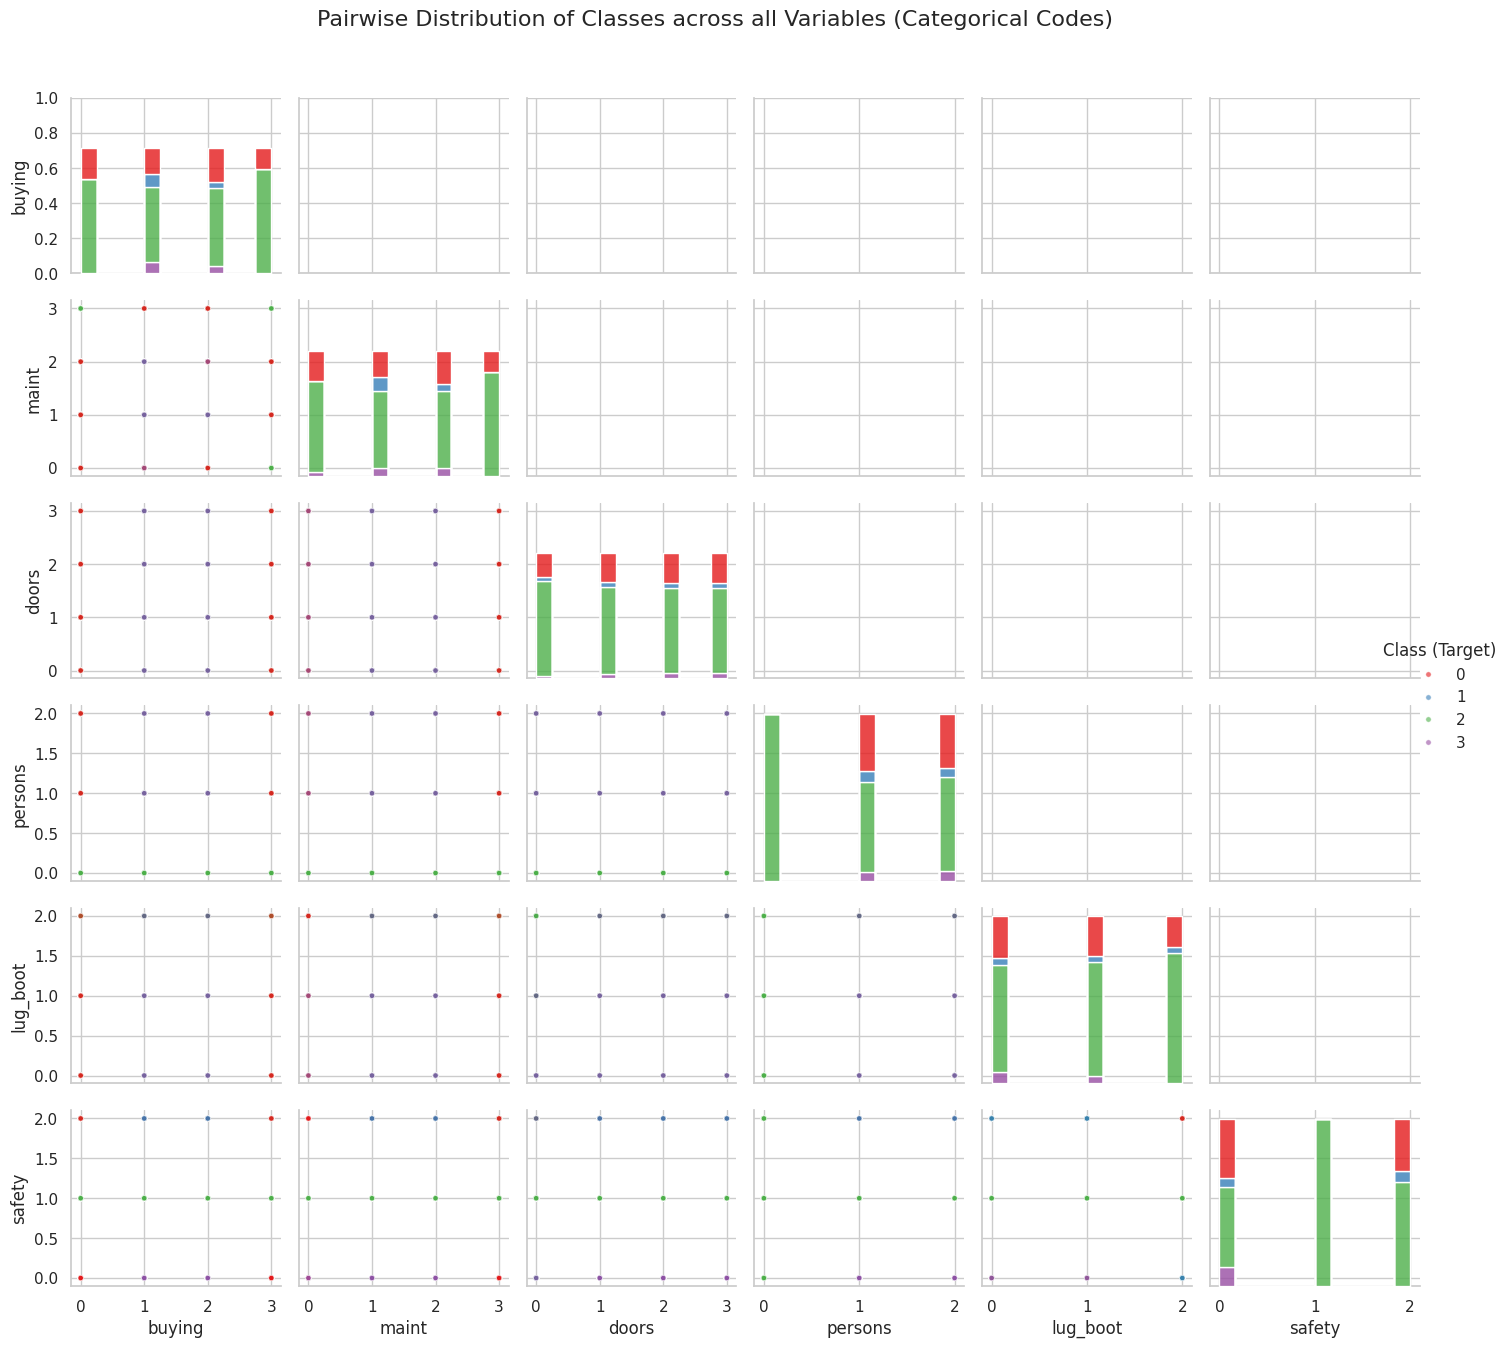

In [119]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 12))

g = sns.PairGrid(df_plot, hue=target_col, palette='Set1', height=2.2, corner=False)

# Нижняя часть матрицы (и верхняя, если убрать corner=False): точки с прозрачностью
g.map_lower(sns.scatterplot, alpha=0.6, s=15, edgecolor='w', linewidth=0.5)

# Диагональ: гистограммы распределения признака, сложенные по классам (stacked)
g.map_diag(sns.histplot, kde=False, element="step", stat="count", multiple="stack", alpha=0.8)

# Добавляем легенду и заголовок
g.add_legend(title='Class (Target)', bbox_to_anchor=(1.05, 0.5))
plt.suptitle("Pairwise Distribution of Classes across all Variables (Categorical Codes)", y=1.02, fontsize=16)

# 5. (Опционально) Подписываем оси оригинальными названиями категорий
plt.tight_layout()
plt.show()

## Stacked Bar Charts (Категориальные графики)

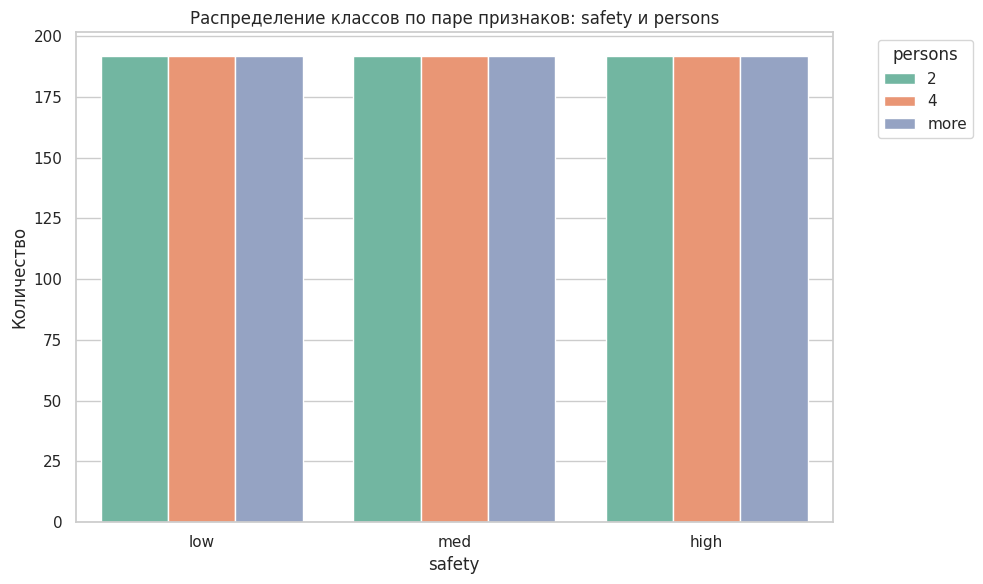

In [120]:
feat1, feat2 = 'safety', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

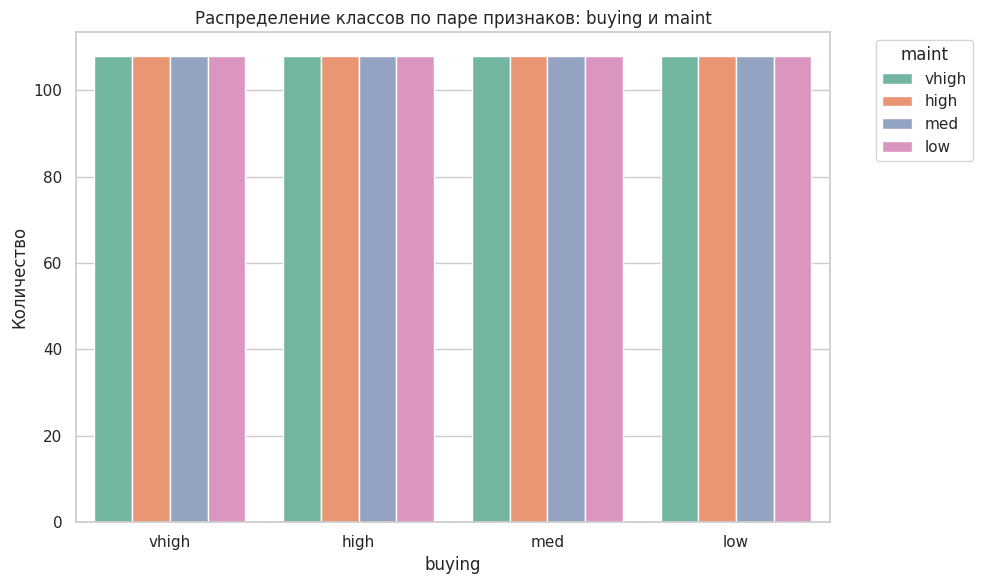

In [79]:
feat1, feat2 = 'buying', 'maint'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

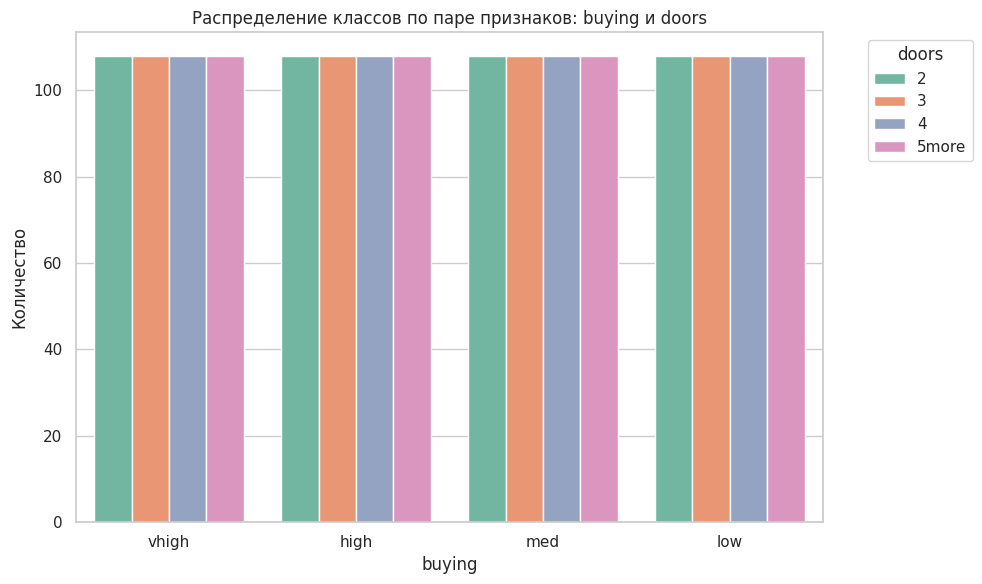

In [80]:
feat1, feat2 = 'buying', 'doors'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

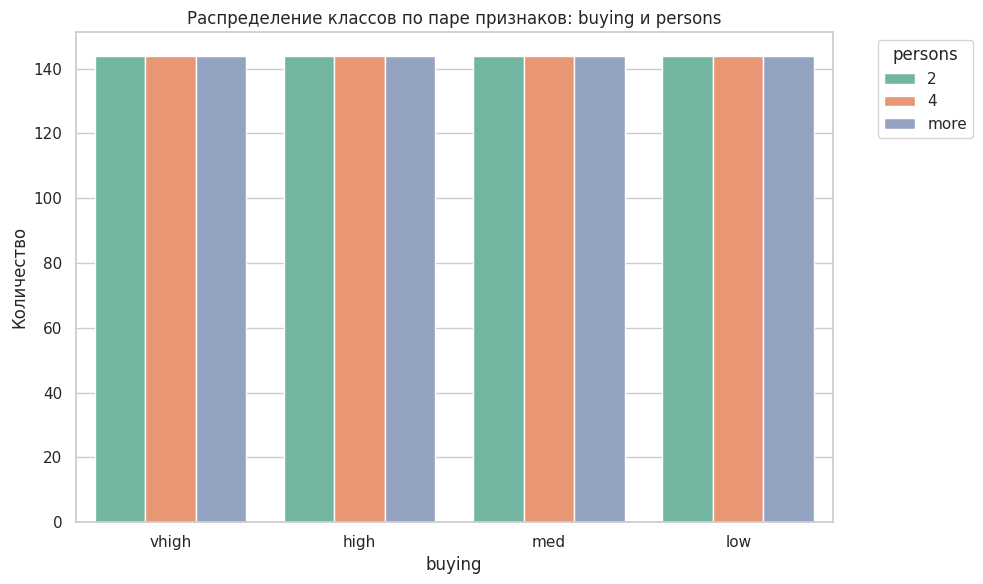

In [81]:
feat1, feat2 = 'buying', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

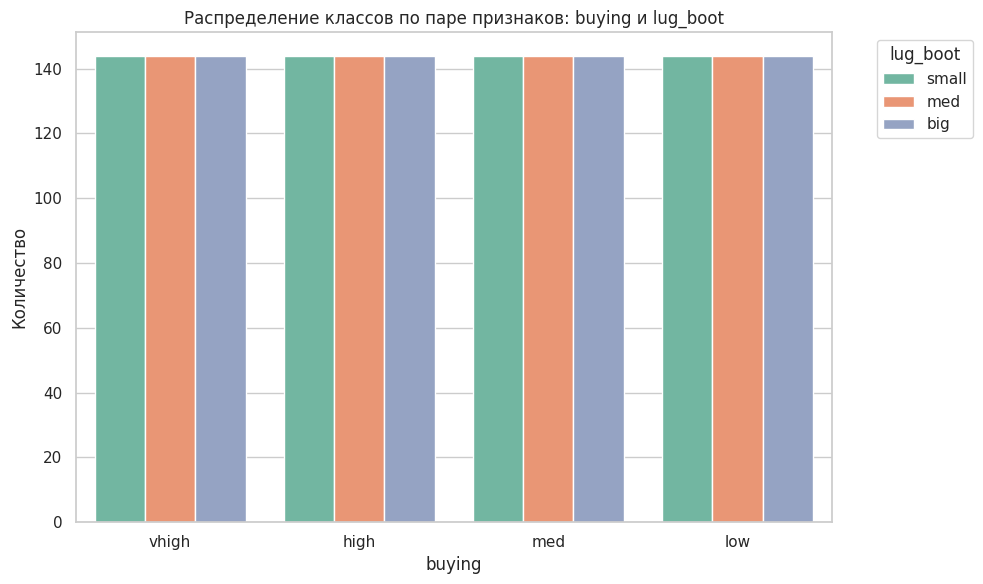

In [82]:
feat1, feat2 = 'buying', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

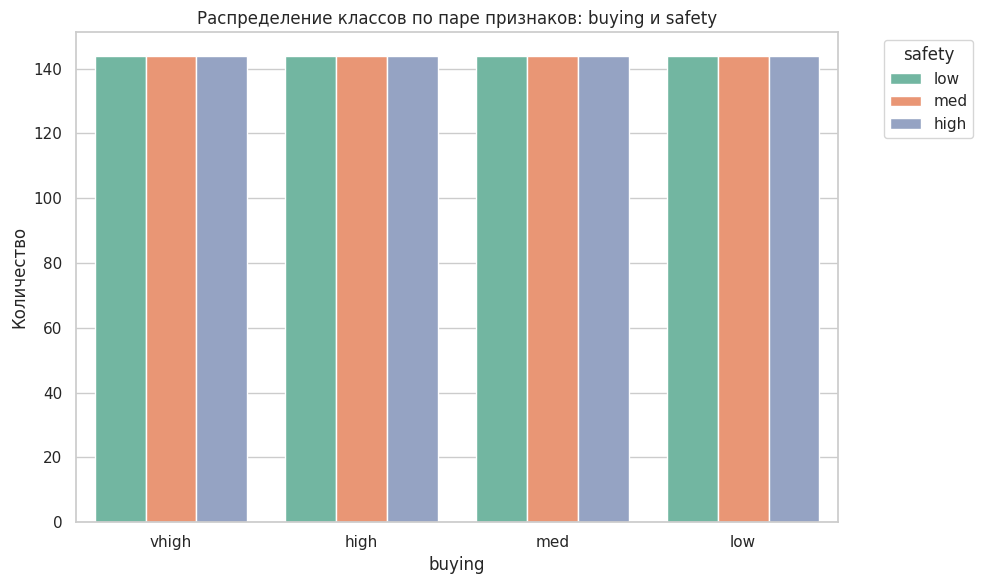

In [83]:
feat1, feat2 = 'buying', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

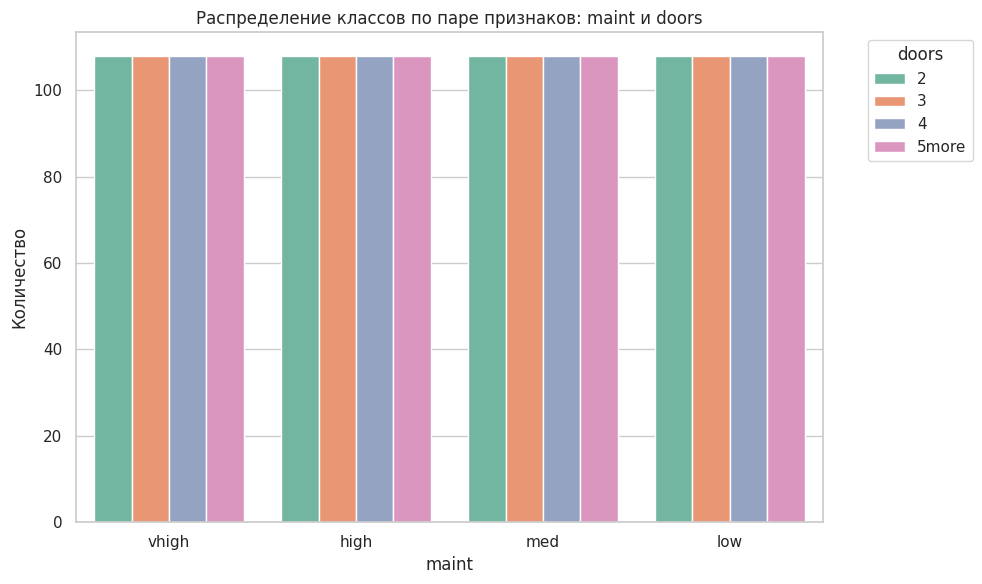

In [84]:
feat1, feat2 = 'maint', 'doors'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

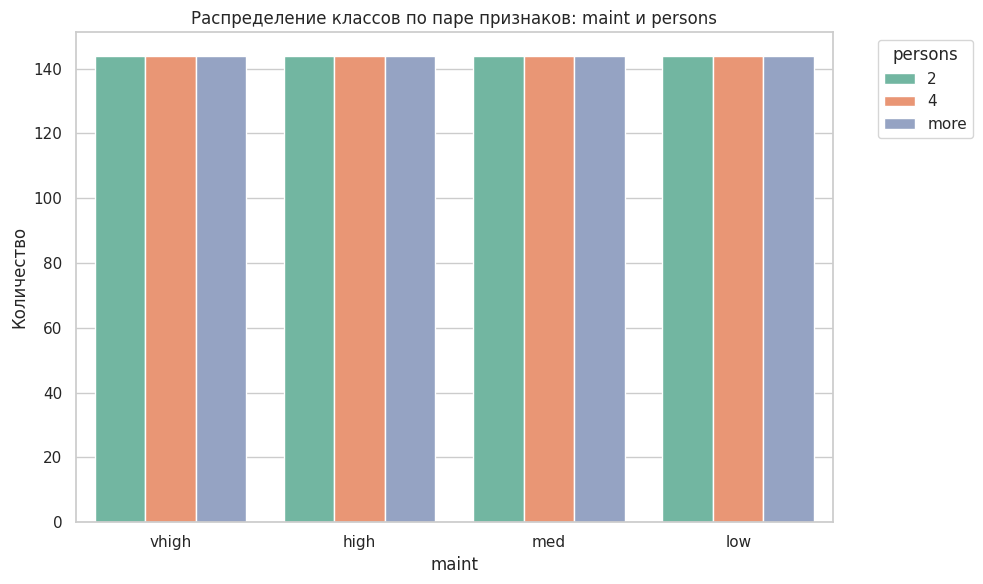

In [85]:
feat1, feat2 = 'maint', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

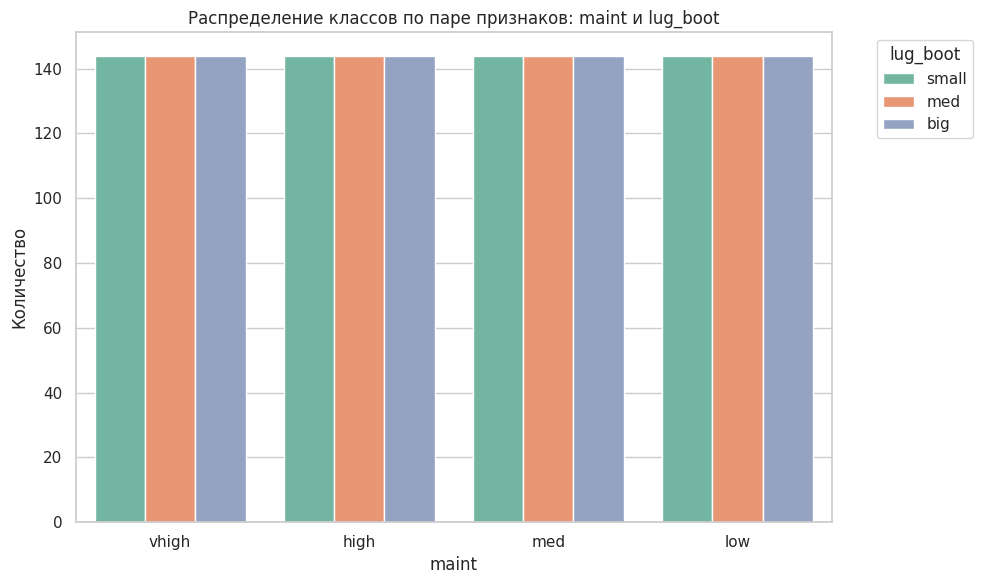

In [86]:
feat1, feat2 = 'maint', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

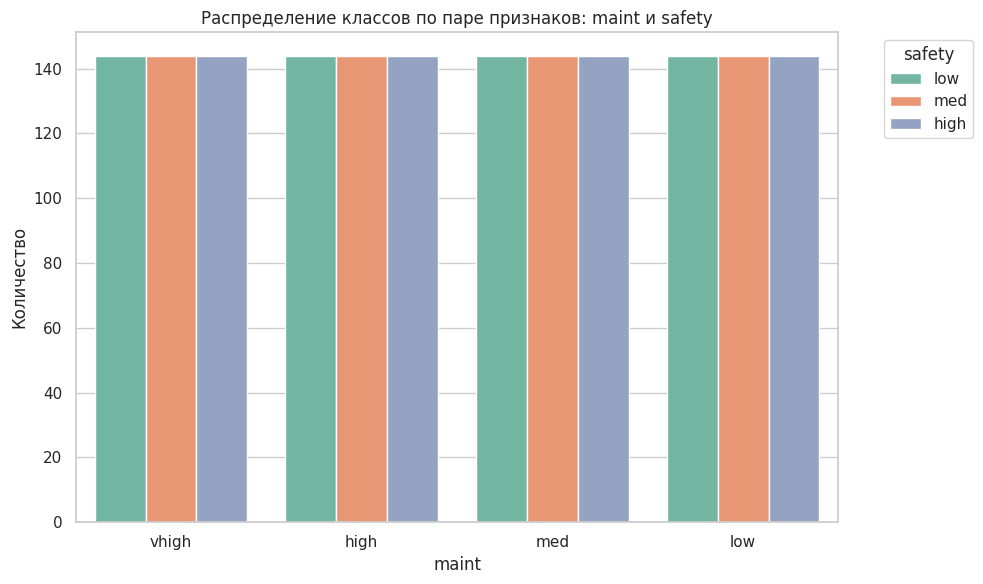

In [87]:
feat1, feat2 = 'maint', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

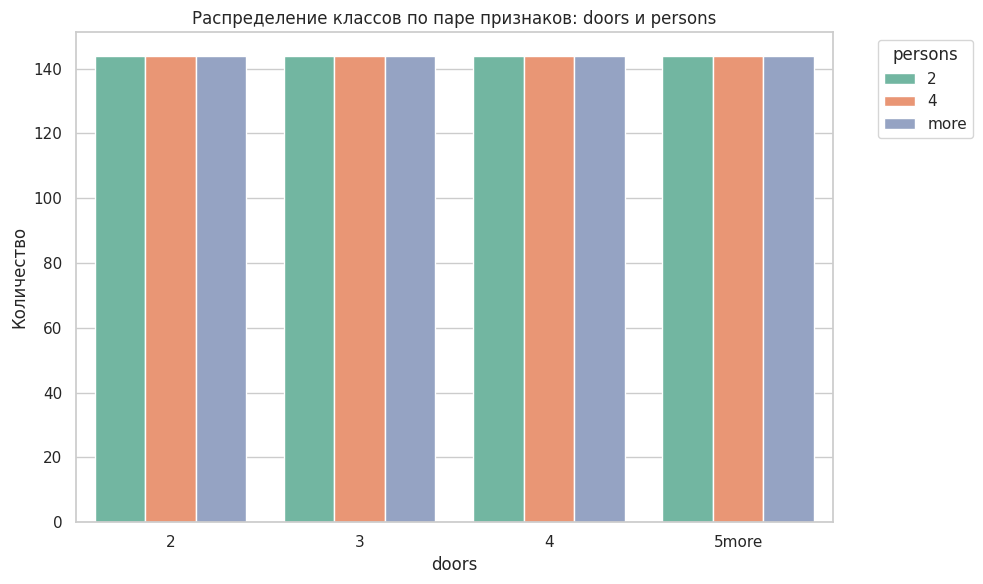

In [88]:
feat1, feat2 = 'doors', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

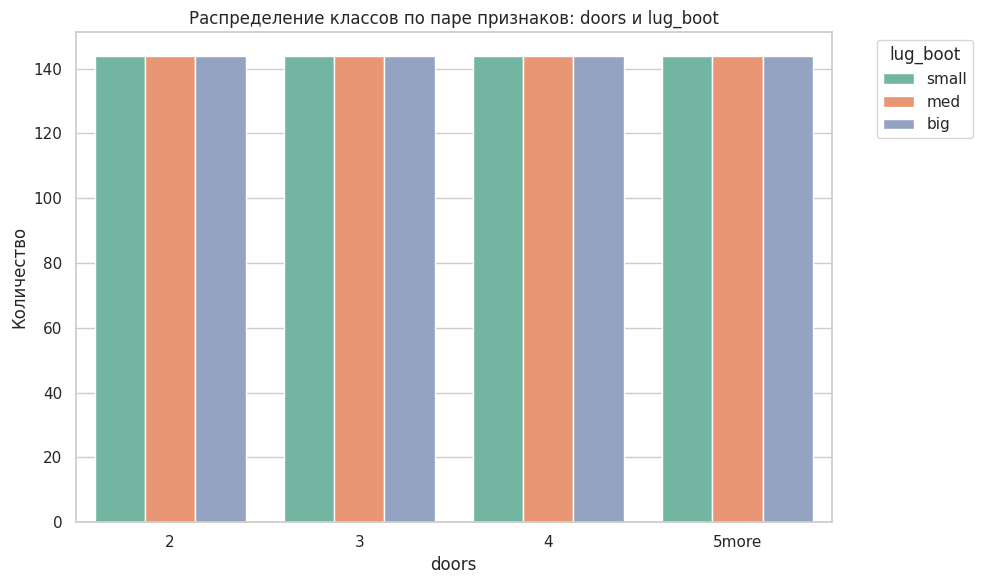

In [89]:
feat1, feat2 = 'doors', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

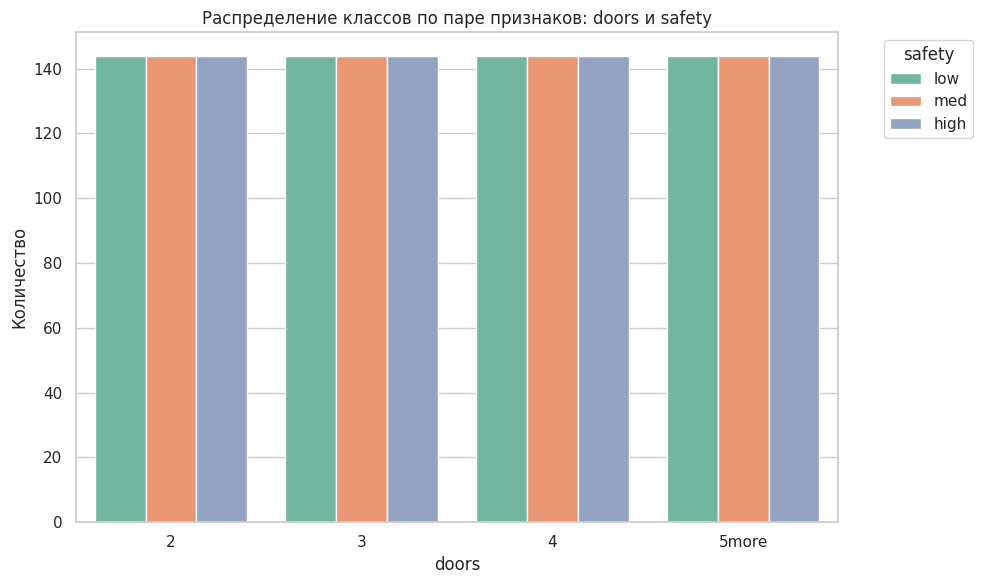

In [90]:
feat1, feat2 = 'doors', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

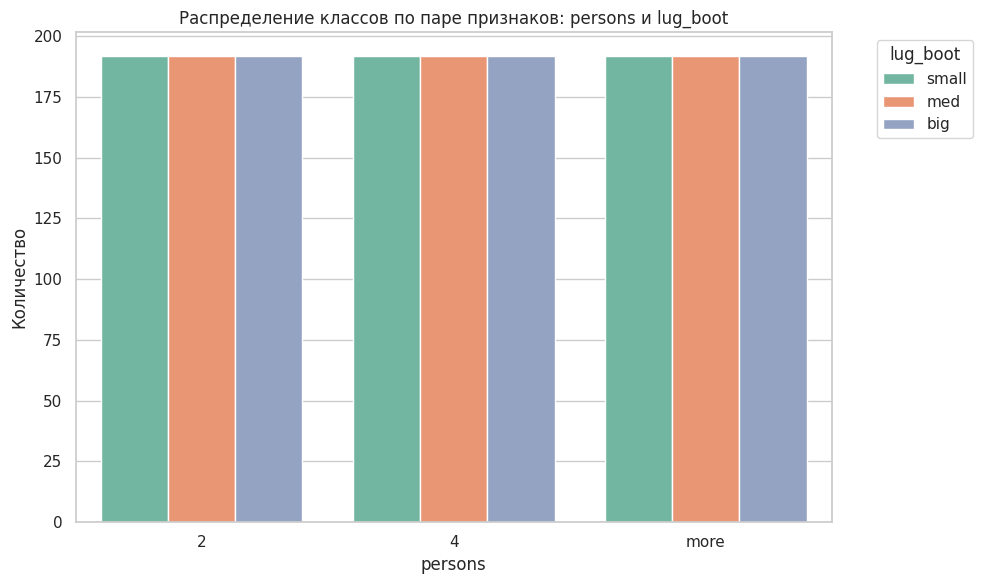

In [91]:
feat1, feat2 = 'persons', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

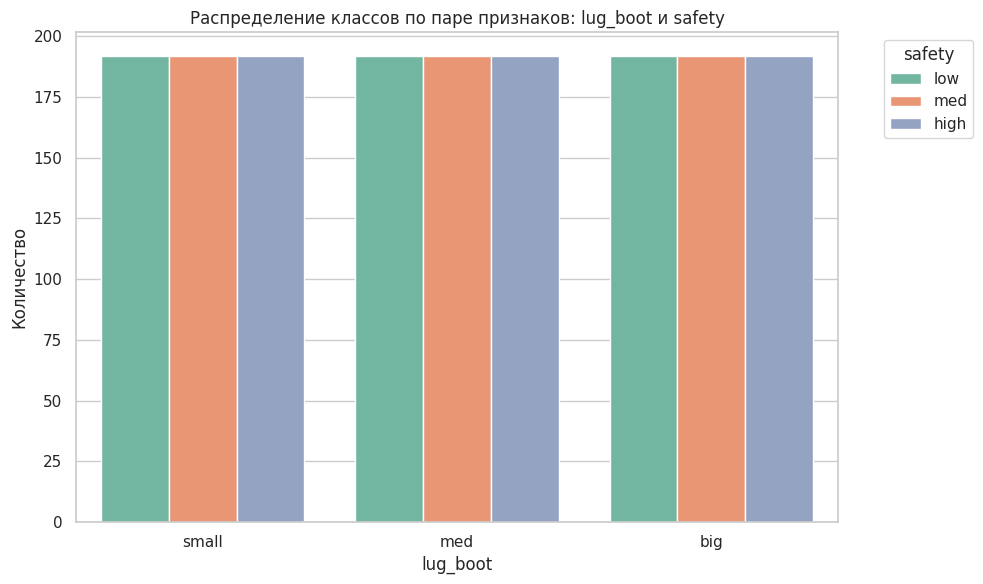

In [92]:
feat1, feat2 = 'lug_boot', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1, hue=feat2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1} и {feat2}')
plt.xlabel(feat1)
plt.ylabel('Количество')
plt.legend(title=feat2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Применение кодирования к DataFrame

In [121]:
df_encoded: pd.DataFrame = df.copy()
for col, mapping in ordinal_mappings.items():
    df_encoded[col] = df_encoded[col].map(mapping)

In [122]:
df_encoded

,buying,maint,doors,persons,lug_boot,safety,class
0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0
2,0,0,0,0,0,2,0
3,0,0,0,0,1,0,0
4,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...
1723,3,3,3,2,1,1,2
1724,3,3,3,2,1,2,3
1725,3,3,3,2,2,0,0
1726,3,3,3,2,2,1,2


## Выделение матрицы признаков и целевой переменной из DataFrame

In [123]:
X_all: pd.DataFrame = df_encoded.drop(columns=[target_col])
y: pd.Series = df_encoded[target_col]

In [124]:
X_all

,buying,maint,doors,persons,lug_boot,safety
0,0,0,0,0,0,0
1,0,0,0,0,0,1
2,0,0,0,0,0,2
3,0,0,0,0,1,0
4,0,0,0,0,1,1
...,...,...,...,...,...,...
1723,3,3,3,2,1,1
1724,3,3,3,2,1,2
1725,3,3,3,2,2,0
1726,3,3,3,2,2,1


In [125]:
y

0       0
1       0
2       0
3       0
4       0
       ..
1723    2
1724    3
1725    0
1726    2
1727    3
Name: class, Length: 1728, dtype: int64

## Выбираем две переменные для визуализации границ

In [126]:
X_2d: pd.DataFrame = df_encoded[[feat1, feat2]]
X_2d

,safety,persons
0,0,0
1,1,0
2,2,0
3,0,0
4,1,0
...,...,...
1723,1,2
1724,2,2
1725,0,2
1726,1,2


## Инициализация моделей

In [127]:
models: Dict[str, Any] = {
    "Линейный дискриминант (LDA)": LinearDiscriminantAnalysis(),
    "Квадратичный дискриминант (QDA)": QuadraticDiscriminantAnalysis(reg_param=0.1, tol=1e-7),
    "Логистическая регрессия": LogisticRegression(
        max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE, tol=1e-7
    ),
    "SVM (линейное ядро)": SVC(kernel='linear', probability=True, random_state=RANDOM_STATE, tol=1e-7),
    "SVM (квадратичное ядро)": SVC(kernel='poly', degree=2, probability=True, random_state=RANDOM_STATE, tol=1e-3)
}

## Визуализация разделяющих кривых для 2D подпространства

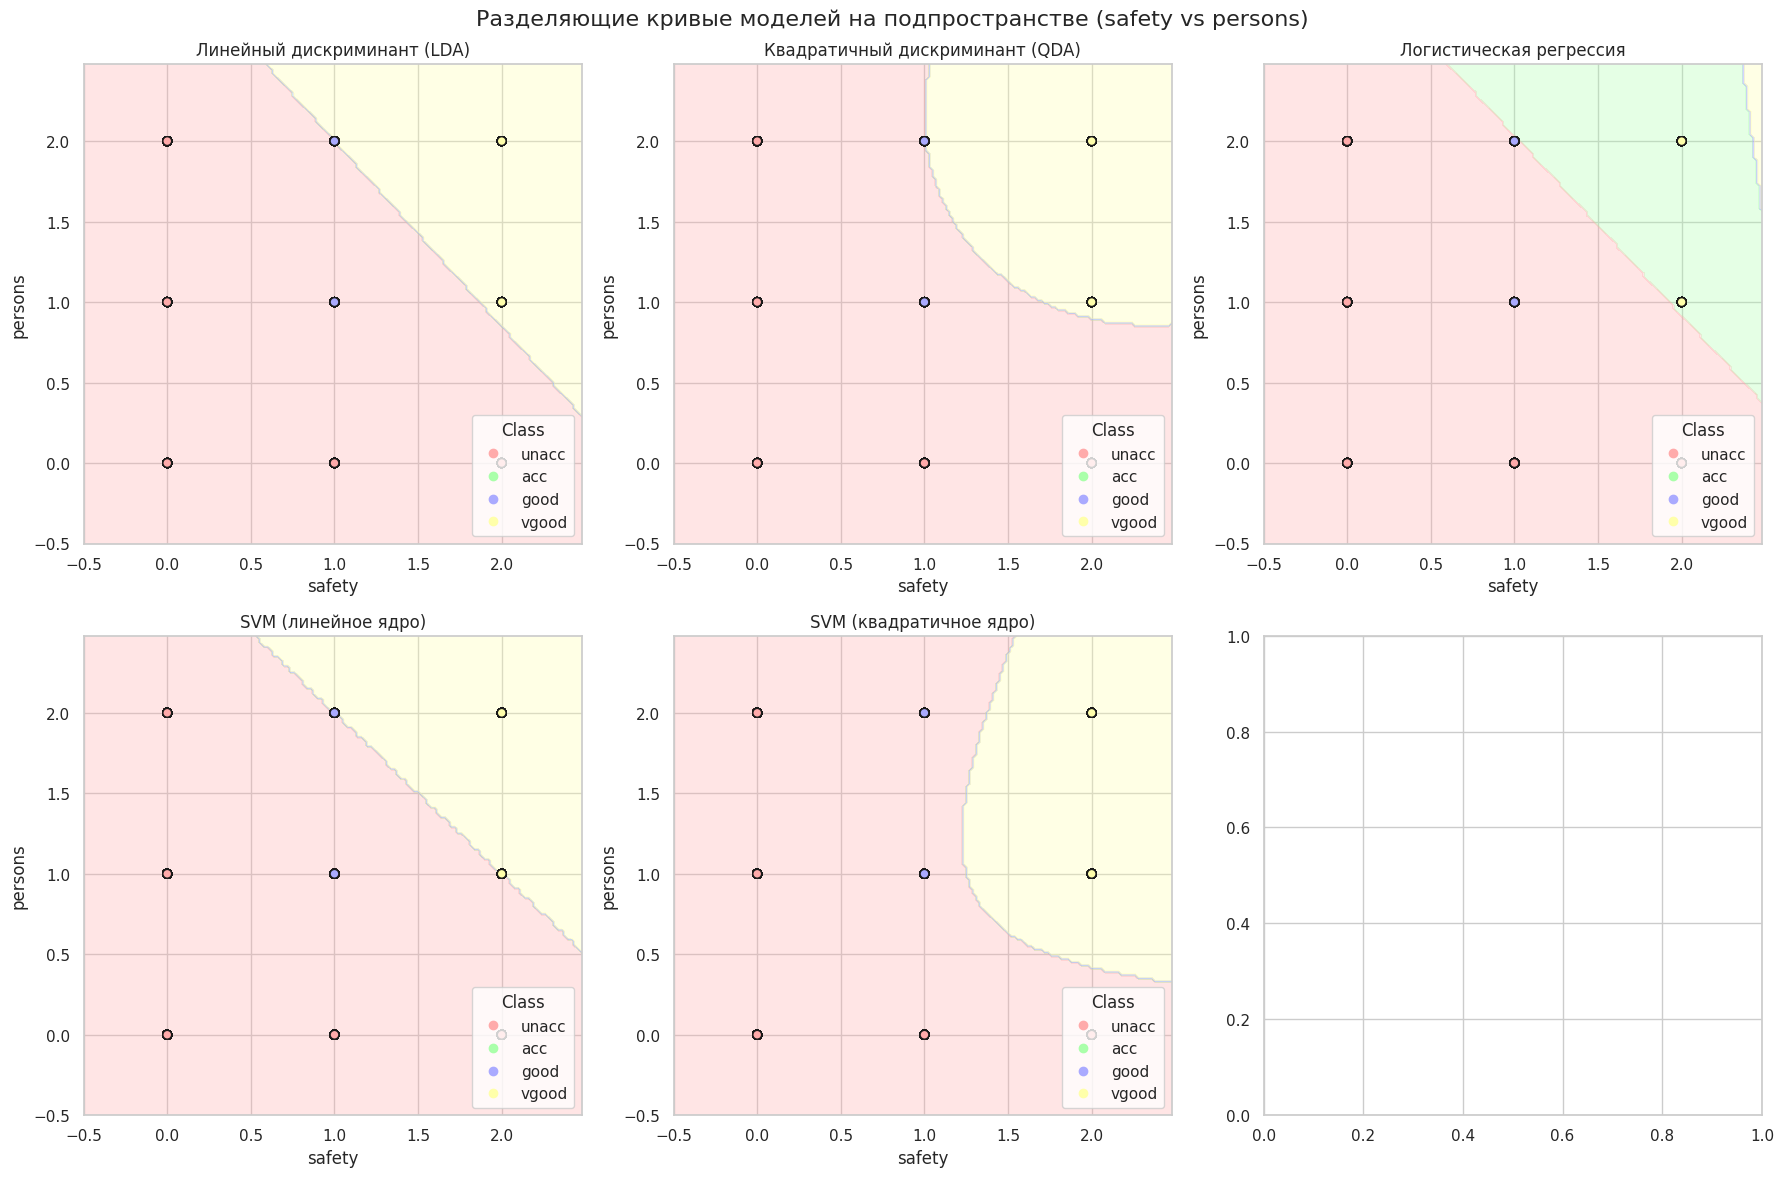

In [128]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d[feat1].min() - 0.5, X_2d[feat1].max() + 0.5
y_min, y_max = X_2d[feat2].min() - 0.5, X_2d[feat2].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d[feat1], X_2d[feat2], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1)
        ax.set_ylabel(feat2)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1)
        ax.set_ylabel(feat2)

plt.suptitle("Разделяющие кривые моделей на подпространстве (safety vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

## Оценка качества (Cross-Validation)

In [129]:
cv: StratifiedKFold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d: np.ndarray = cross_val_score(model, X_2d, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d.mean():.4f} (+/- {scores_2d.std()*2:.4f})     | {scores_all.mean():.4f} (+/- {scores_all.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7674 (+/- 0.0258)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7691 (+/- 0.0202)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7691 (+/- 0.0202)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7743 (+/- 0.0243)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7691 (+/- 0.0202)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


## Матрица ошибок

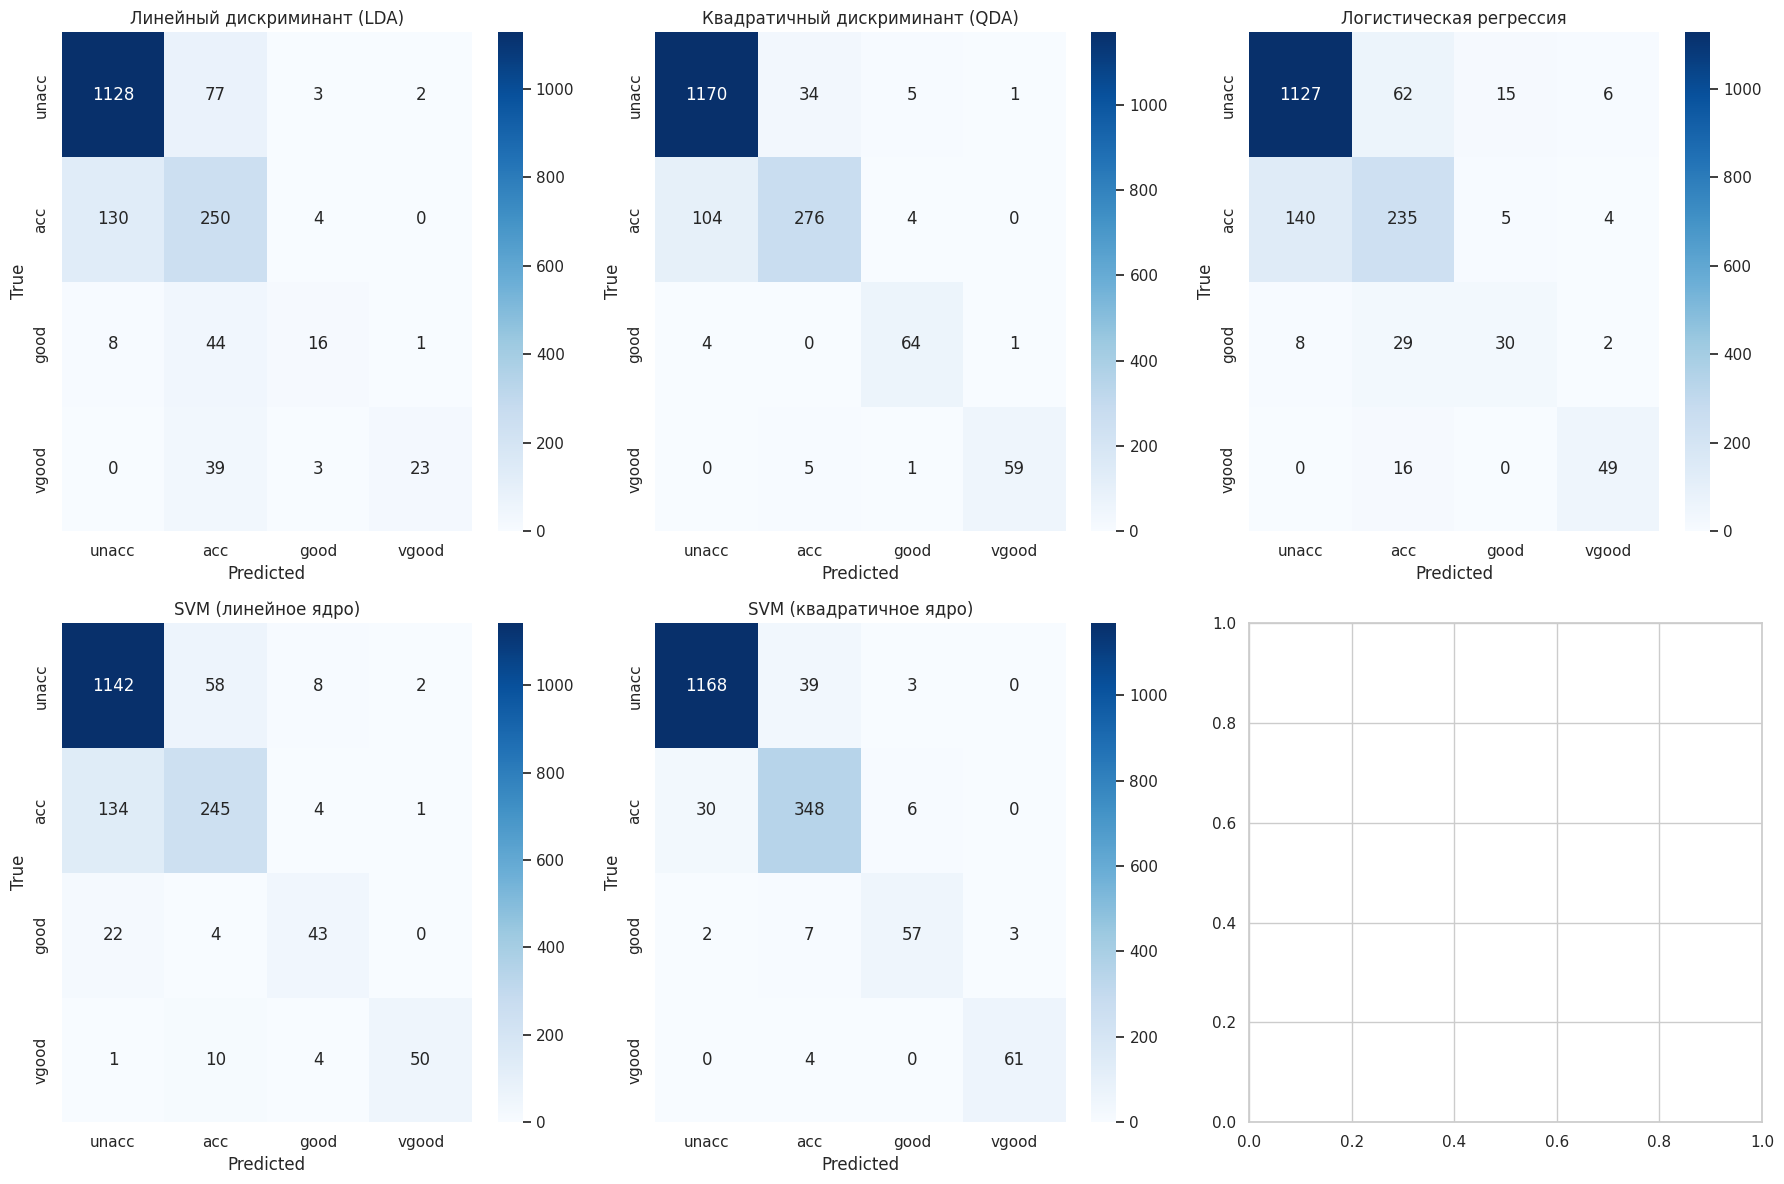


Классификационный отчёт для LDA:
              precision    recall  f1-score   support

       unacc       0.89      0.93      0.91      1210
         acc       0.61      0.65      0.63       384
        good       0.62      0.23      0.34        69
       vgood       0.88      0.35      0.51        65

    accuracy                           0.82      1728
   macro avg       0.75      0.54      0.60      1728
weighted avg       0.82      0.82      0.81      1728



In [132]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_all, y)
    y_pred = model.predict(X_all)
    
    ax = axes[i]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['unacc', 'acc', 'good', 'vgood'],
                yticklabels=['unacc', 'acc', 'good', 'vgood'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Текстовый отчёт для лучшей модели
print("\nКлассификационный отчёт для LDA:")
lda_full = LinearDiscriminantAnalysis()
lda_full.fit(X_all, y)
print(classification_report(y, lda_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))

## Кривые обучения (Learning Curves)

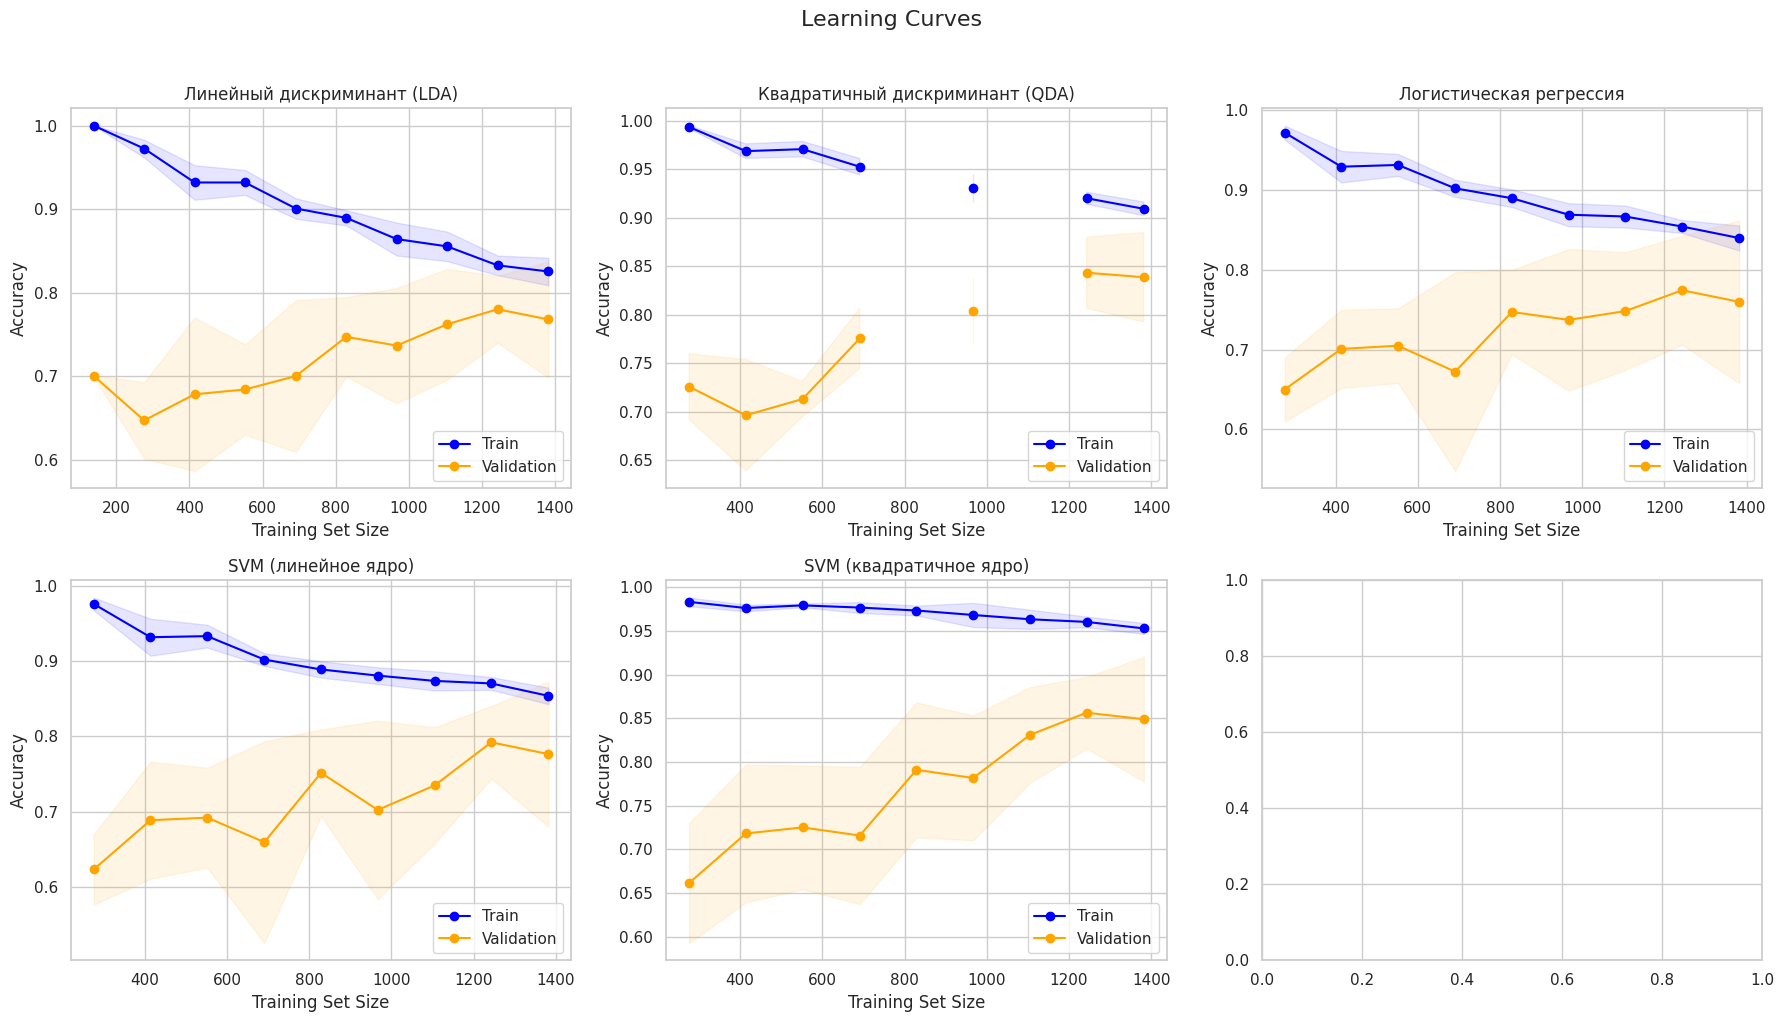

In [137]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_all, y, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=RANDOM_STATE
    )
    
    ax = axes[i]
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    
    ax.plot(train_sizes, train_mean, 'o-', label='Train', color='blue')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation', color='orange')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='orange')
    
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('Accuracy')
    ax.set_title(name)
    ax.legend(loc='lower right')
    ax.grid(True)

plt.suptitle('Learning Curves', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## Калибровка вероятностей (Calibration Curves)

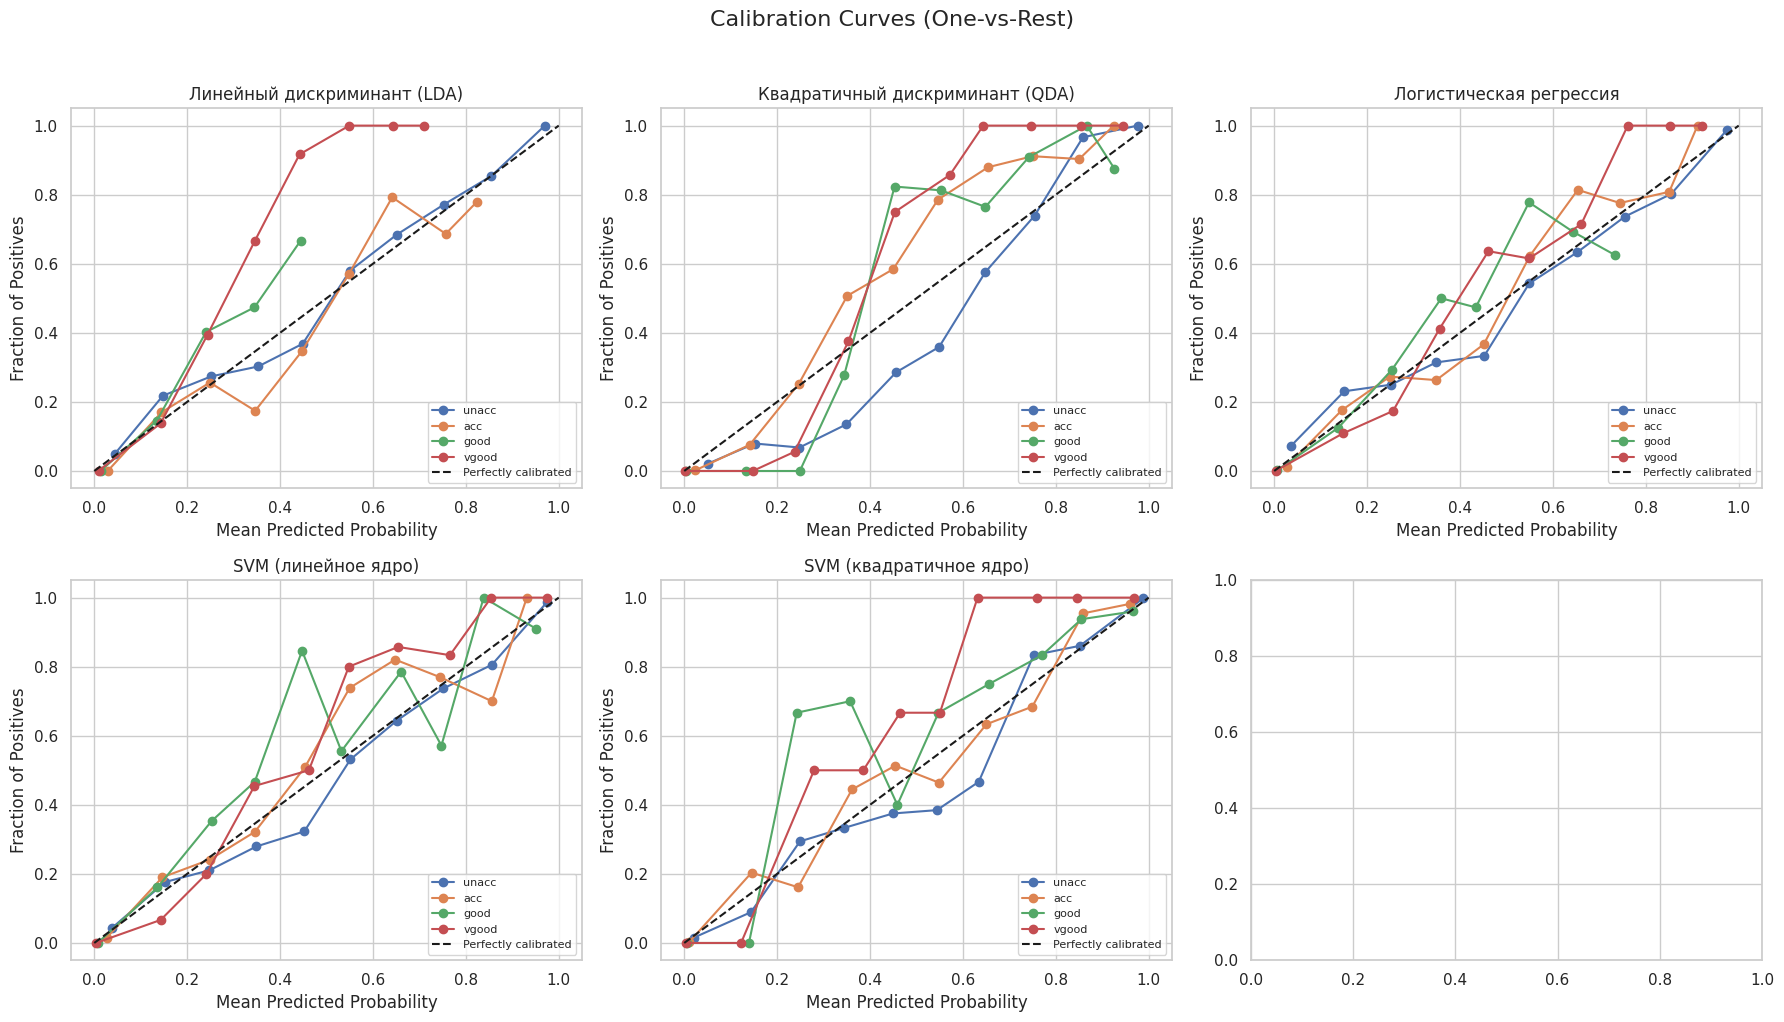

In [138]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_all, y)
    
    # Для многоклассовой задачи используем one-vs-rest
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_all)
        
        ax = axes[i]
        for j, class_name in enumerate(['unacc', 'acc', 'good', 'vgood']):
            y_true_binary = (y == j).astype(int)
            prob_true, prob_pred = calibration_curve(y_true_binary, y_prob[:, j], n_bins=10)
            
            ax.plot(prob_pred, prob_true, 'o-', label=class_name)
        
        ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
        ax.set_xlabel('Mean Predicted Probability')
        ax.set_ylabel('Fraction of Positives')
        ax.set_title(name)
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True)
    else:
        axes[i].text(0.5, 0.5, 'No probability estimates', 
                    ha='center', va='center', transform=axes[i].transAxes)

plt.suptitle('Calibration Curves (One-vs-Rest)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## SHAP анализ для интерпретации

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


TypeError: The shap_values argument must be an Explanation object, Cohorts object, or dictionary of Explanation objects!

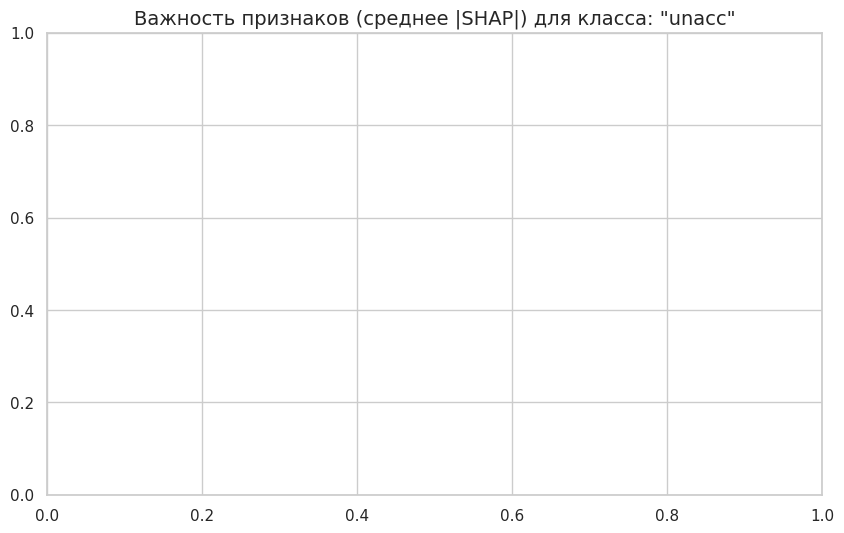

In [ ]:
# 1. Обучаем модель
lr_model = LogisticRegression(max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE)
lr_model.fit(X_all, y)

# 2. Создаем explainer
# max_samples=1728 убирает предупреждение и использует весь датасет
explainer = shap.LinearExplainer(lr_model, X_all, max_samples=1728)

# Для многоклассовой задачи это вернет список из 4-х numpy-массивов
shap_values = explainer.shap_values(X_all)

class_names = ['unacc', 'acc', 'good', 'vgood']

# 3. Визуализация SHAP-значений для каждого класса по отдельности
for i, class_name in enumerate(class_names):
    plt.figure(figsize=(10, 6))
    plt.title(f'Влияние признаков на предсказание класса: "{class_name}"', fontsize=14)
    
    # shap.summary_plot отлично принимает numpy-массивы.
    # Мы просто НЕ передаем параметр ax, и shap сам корректно отрисует график.
    shap.summary_plot(shap_values[i], X_all, max_display=6)
    
    plt.tight_layout()
    plt.show()

## Тепловая карта корреляций между признаками

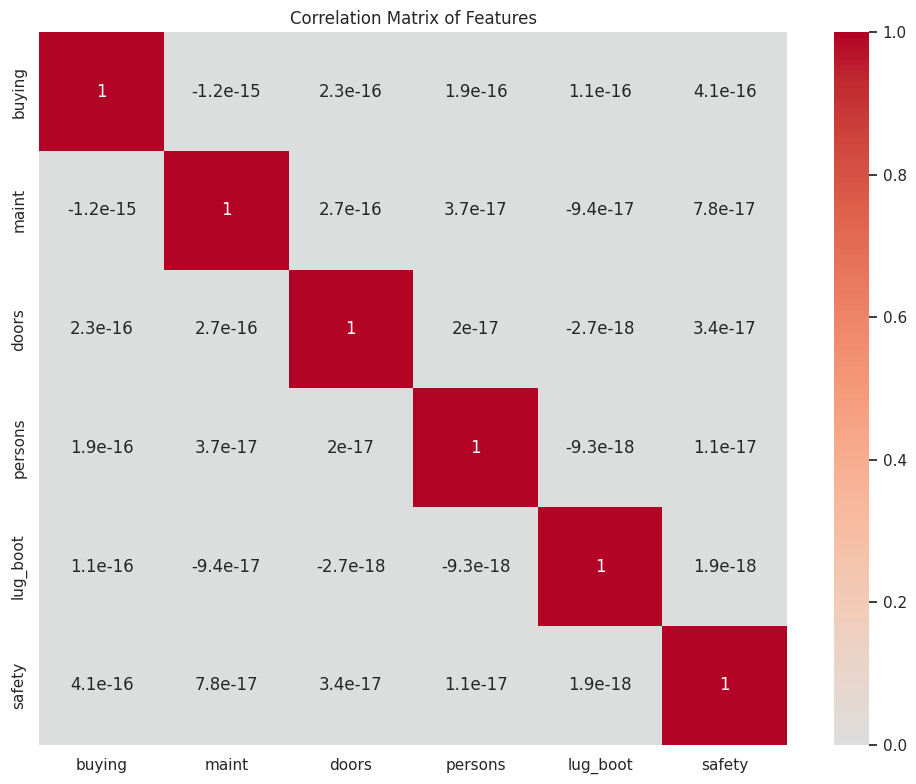

In [143]:
plt.figure(figsize=(10, 8))
corr_matrix = X_all.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Features')
plt.tight_layout()
plt.show()

## Подбор гиперпараметров с Optuna

In [142]:
def objective(trial):
    C = trial.suggest_float('C', 1e-4, 10, log=True)
    model = LogisticRegression(C=C, max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE)
    scores = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print(f"Best C: {study.best_params['C']:.4f}")
print(f"Best accuracy: {study.best_value:.4f}")

Best C: 0.1382
Best accuracy: 0.7633


## Обучение LinearDiscriminantAnalysis (LDA) на всем признаковом пространстве и настройки

In [133]:
lda_full: LinearDiscriminantAnalysis = LinearDiscriminantAnalysis()
lda_full.fit(X_all, y)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


## Анализ важности признаков в LDA

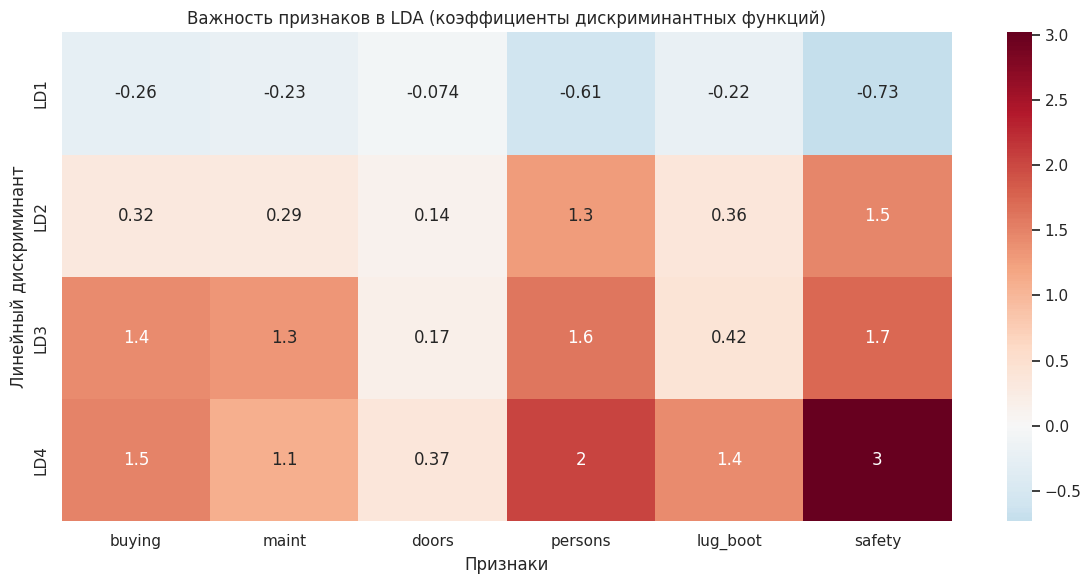

In [134]:
coef_df = pd.DataFrame(
    lda_full.coef_, 
    columns=X_all.columns,
    index=[f'LD{i+1}' for i in range(lda_full.coef_.shape[0])]
)

plt.figure(figsize=(12, 6))
sns.heatmap(coef_df, annot=True, cmap='RdBu_r', center=0)
plt.title('Важность признаков в LDA (коэффициенты дискриминантных функций)')
plt.ylabel('Линейный дискриминант')
plt.xlabel('Признаки')
plt.tight_layout()
plt.show()

In [135]:
y_pred: np.ndarray = lda_full.predict(X_all)

feature_names: List[str] = X_all.columns.tolist()
pairs: List[Tuple[str, str]] = list(combinations(feature_names, 2)) # Все 15 пар

markers: List[str] = ['o', 's', '^', 'D'] 
class_names: List[str] = ['unacc', 'acc', 'good', 'vgood']

In [146]:
print(f"Cohen's Kappa: {cohen_kappa_score(y, y_pred):.4f}")
print(f"Matthews Correlation Coefficient: {matthews_corrcoef(y, y_pred):.4f}")

Cohen's Kappa: 0.5844
Matthews Correlation Coefficient: 0.5871


## Построение графиков

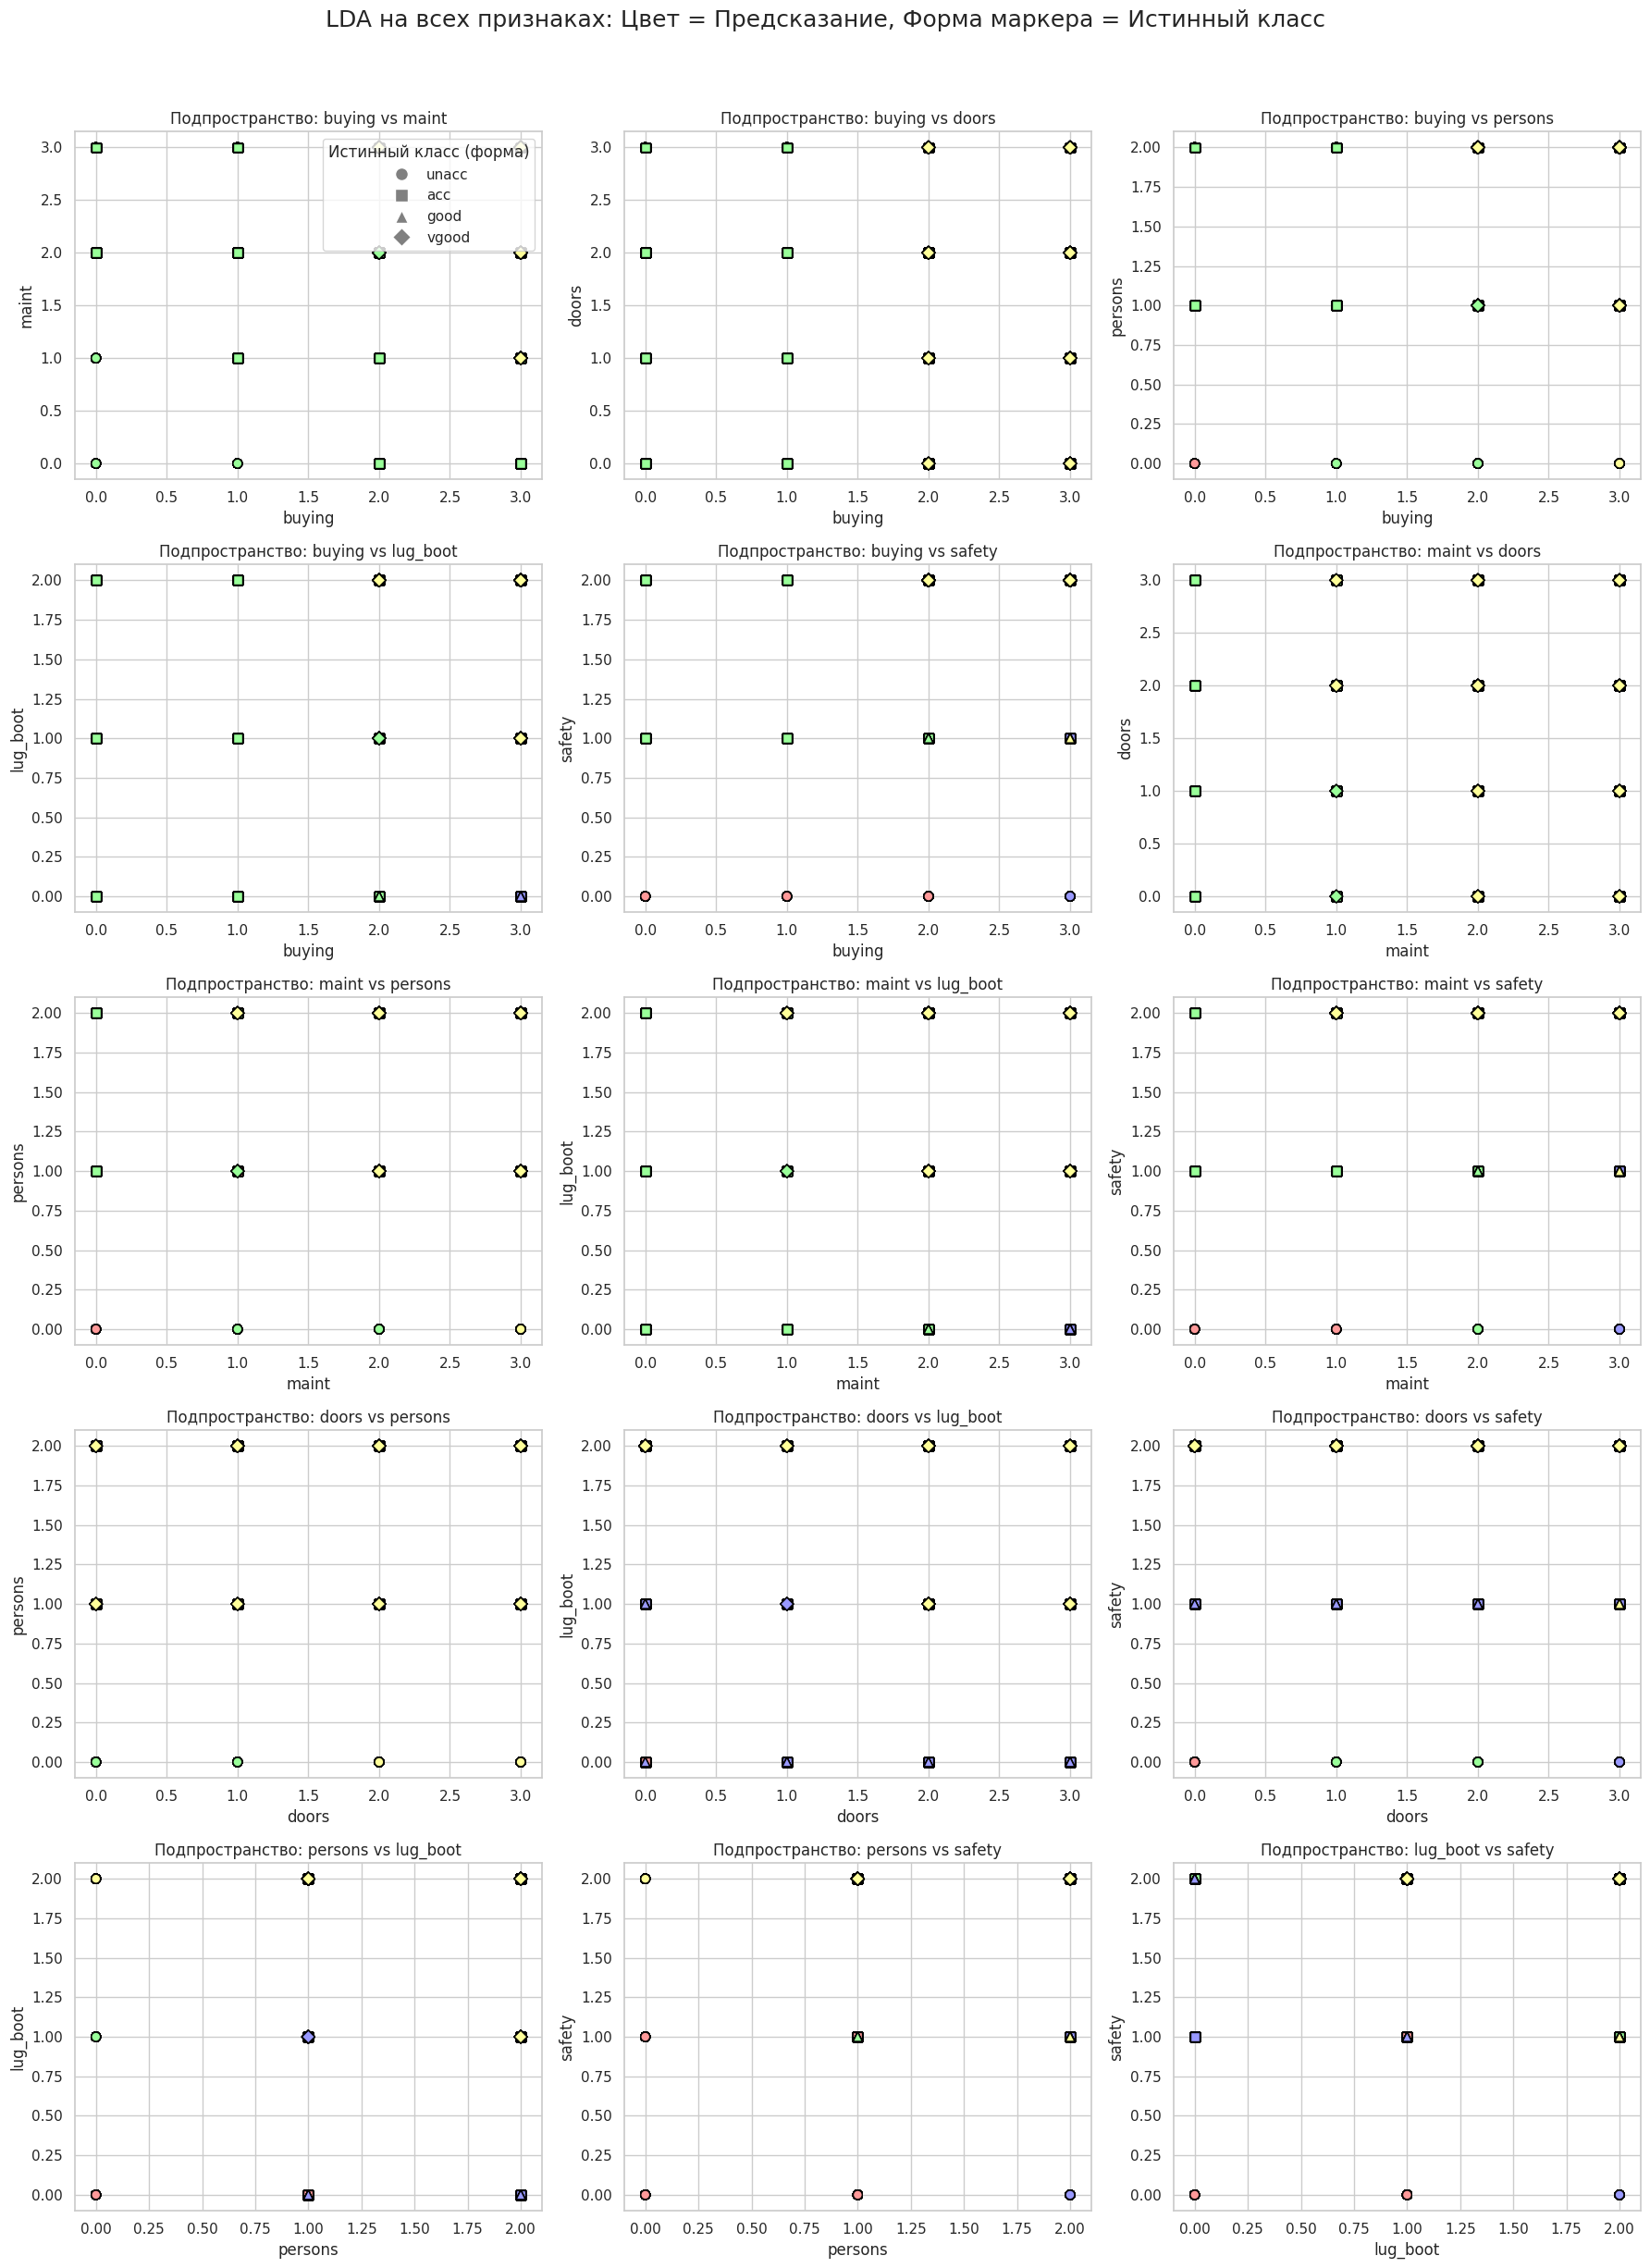

In [136]:
fig, axes = plt.subplots(5, 3, figsize=(18, 25))
axes = axes.flatten()

cmap_pred: ListedColormap = ListedColormap(['#FF9999', '#99FF99', '#9999FF', '#FFFF99'])

for idx, (f1, f2) in enumerate(pairs):
    ax = axes[idx]
    
    for true_class in range(4):
        mask: pd.Series = (y == true_class)
        ax.scatter(
            X_all.loc[mask, f1], 
            X_all.loc[mask, f2], 
            c=y_pred[mask],          # Цвет = ответ алгоритма
            cmap=cmap_pred, 
            marker=markers[true_class], # Форма = истинный класс
            edgecolor='black',
            s=50,
            vmin=0, vmax=3,
            label=class_names[true_class]
        )
    
    ax.set_xlabel(f1)
    ax.set_ylabel(f2)
    ax.set_title(f"Подпространство: {f1} vs {f2}")
    
    # Легенда графика
    if idx == 0:
        legend_elements = [plt.Line2D([0], [0], marker=markers[i], color='w', 
                                      markerfacecolor='gray', markersize=10, label=class_names[i]) 
                           for i in range(4)]
        ax.legend(handles=legend_elements, title="Истинный класс (форма)", loc='upper right')

plt.suptitle("LDA на всех признаках: Цвет = Предсказание, Форма маркера = Истинный класс", fontsize=18, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()